/home/viplab/anaconda3/envs/cnet2/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


正在实例化数据集...
dataset name: /data/train/train_30/
json collected
folders collected
folders len 48000
groups len 12000

数据集大小: 12000 个样本
每个样本包含4个视角

获取样本 0...

image shape: (4, 4, 64, 64), dtype: float32
image range: [0.000, 1.000]

cond shape: (4, 48, 512, 512), dtype: float64
cond range: [0.014, 0.860]

text: city topview from camera, camera conf as following. {camera_height:100.0,tilt_deg:30.0,lens:100.0}...


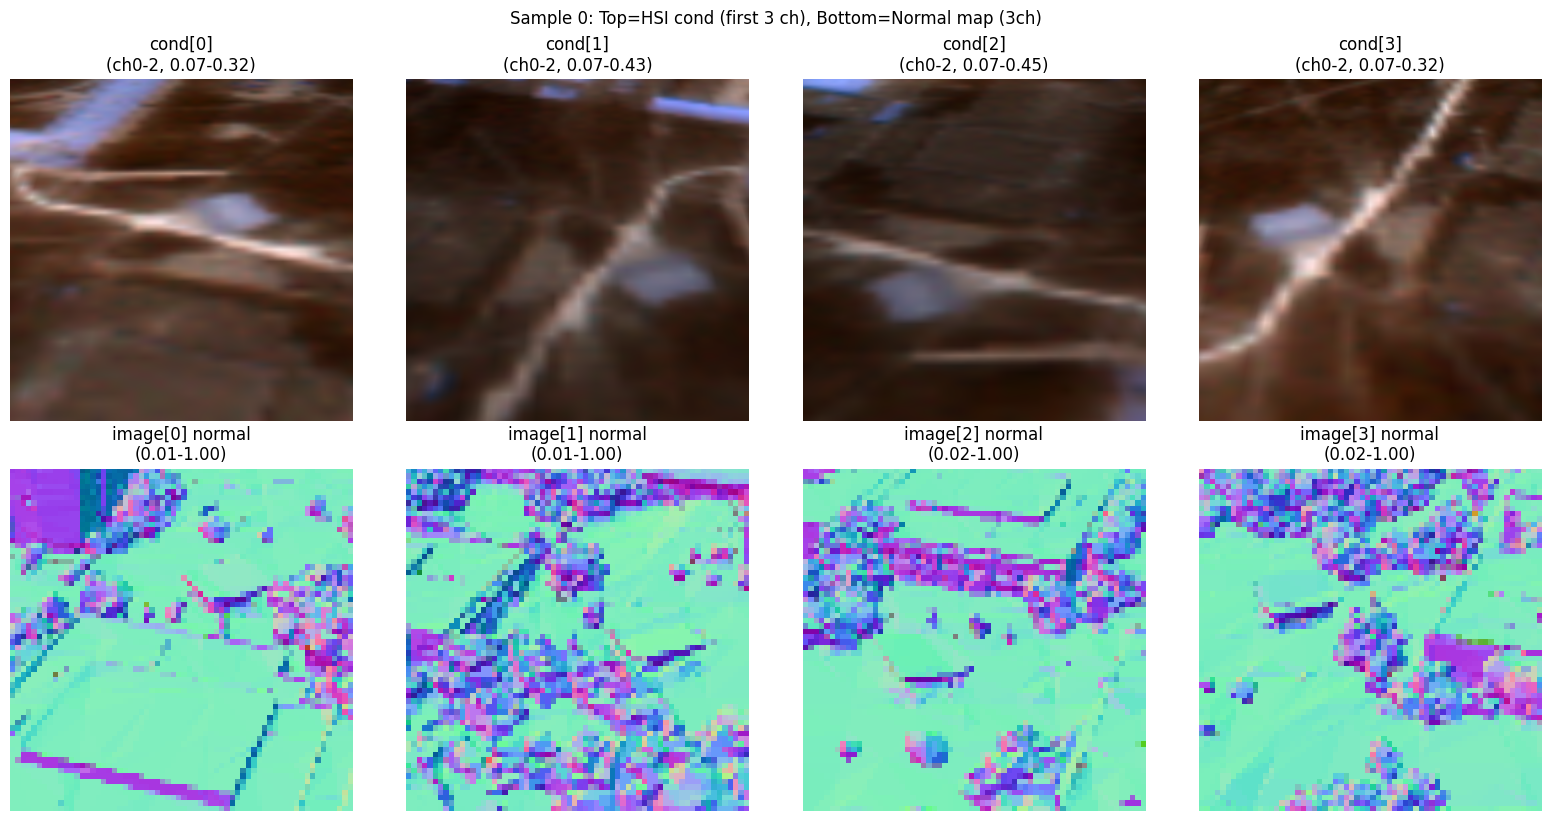

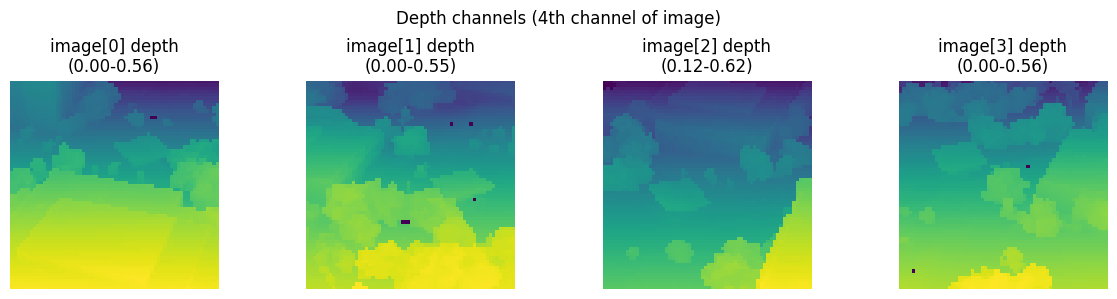


可视化完成！


In [1]:
import matplotlib.pyplot as plt
import numpy as np
from cnet_dataset import HSIControlNetDataset

# ==================== 配置路径 ====================
ROOT_DIR = '/data/train/train_30/'  # 修改为你的数据路径

print("=" * 50)
print("正在实例化数据集...")
print("=" * 50)

# 实例化数据集
dataset = HSIControlNetDataset(
    root_dir=ROOT_DIR,
    image_size=64,           # 根据你的配置
    condition_image_scale=8   # 64 * 8 = 512
)

print(f"\n数据集大小: {len(dataset)} 个样本")
print(f"每个样本包含4个视角")

# 获取第一个样本
idx = 0
print(f"\n获取样本 {idx}...")
data = dataset[idx]

image = data['image']           # (4, 4, 64, 64)
cond = data['conditioning_image']  # (4, 48, 512, 512)

print(f"\nimage shape: {image.shape}, dtype: {image.dtype}")
print(f"image range: [{image.min():.3f}, {image.max():.3f}]")

print(f"\ncond shape: {cond.shape}, dtype: {cond.dtype}")
print(f"cond range: [{cond.min():.3f}, {cond.max():.3f}]")

print(f"\ntext: {data['text'][:100]}...")

# ==================== 可视化 ====================

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for i in range(4):
    # 上面一行：cond，取前3个通道作为RGB显示
    cond_img = cond[i, :3, :, :].copy()  # (3, 512, 512)
    cond_img = np.transpose(cond_img, (1, 2, 0))  # (512, 512, 3)
    # 归一化到0-1用于显示
    cond_min, cond_max = cond_img.min(), cond_img.max()
    cond_img = (cond_img - cond_min) / (cond_max - cond_min + 1e-8)
    
    axes[0, i].imshow(cond_img)
    axes[0, i].set_title(f'cond[{i}]\n(ch0-2, {cond_min:.2f}-{cond_max:.2f})')
    axes[0, i].axis('off')
    
    # 下面一行：image，取前3个通道（normal的3通道）显示
    img = image[i, :3, :, :].copy()  # (3, 64, 64)
    img = np.transpose(img, (1, 2, 0))  # (64, 64, 3)
    # 归一化
    img_min, img_max = img.min(), img.max()
    img = (img - img_min) / (img.max() - img_min + 1e-8)
    
    axes[1, i].imshow(img)
    axes[1, i].set_title(f'image[{i}] normal\n({img_min:.2f}-{img_max:.2f})')
    axes[1, i].axis('off')

plt.tight_layout()
plt.suptitle(f'Sample {idx}: Top=HSI cond (first 3 ch), Bottom=Normal map (3ch)', y=1.02)
plt.show()

# 额外：显示image的第4通道（depth）
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for i in range(4):
    depth = image[i, 3, :, :].copy()  # (64, 64)
    d_min, d_max = depth.min(), depth.max()
    axes[i].imshow(depth, cmap='viridis')
    axes[i].set_title(f'image[{i}] depth\n({d_min:.2f}-{d_max:.2f})')
    axes[i].axis('off')
plt.suptitle('Depth channels (4th channel of image)')
plt.tight_layout()
plt.show()

print("\n可视化完成！")